In [8]:
import json
with open("../outputs/hpo/phase_1/outputs.json", "r") as f:
    hpo_data = json.load(f)
with open("./baseline_metrics.json", "r") as f:
    baseline_metrics = json.load(f)

In [9]:
trial_scores = {}
for trial in hpo_data.keys():
    trial_scores[trial] = {}

for dataset_name in ("nt_benchmark", "genomic_benchmark", "bend_benchmark", "chromatin_profile_prediction"):
    def get_tasks(trial):
        global dataset_name
        if dataset_name == "chromatin_profile_prediction":
            cpp = trial.get("chromatin_profile_prediction")
            if cpp is not None:
                return {"chromatin_profile_prediction": cpp}
            else:
                return None
        else:
            return trial.get(dataset_name)

    for trial in hpo_data.keys():
        tasks = get_tasks(hpo_data[trial])

        if tasks is not None:
            for name, val in tasks.items():
                if name == "pretraining": 
                    continue
                trial_scores[trial][name] = val[0][baseline_metrics[name]["metric"]]

In [10]:
# Cleanup
for trial_key in list(trial_scores.keys()):
    if len(trial_scores[trial_key]) != 30:
        del trial_scores[trial_key]

In [11]:
from copy import deepcopy
z_scores = deepcopy(trial_scores)

# Turn trial_scores into z_scores
for trial in trial_scores:
    for task in trial_scores[trial]:
        dataset_metrics = baseline_metrics[task]
        score = trial_scores[trial][task]
        score = (score - dataset_metrics["mean"]) / dataset_metrics["std"]
        z_scores[trial][task] = score

In [12]:
tasks_names = list(z_scores["1"].keys())
grouped_scores = {}
for task in tasks_names:
    grouped_scores[task] = []
    for trial in sorted(z_scores.keys()): # Constant order
        grouped_scores[task].append(z_scores[trial][task])

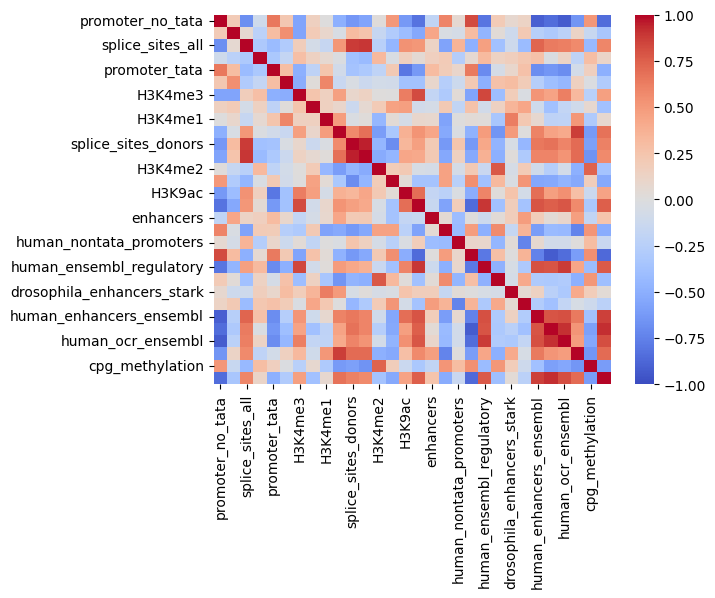

In [18]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
df = pd.DataFrame(grouped_scores)
spearman_matrix = df.corr(method='spearman')
sns.heatmap(spearman_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

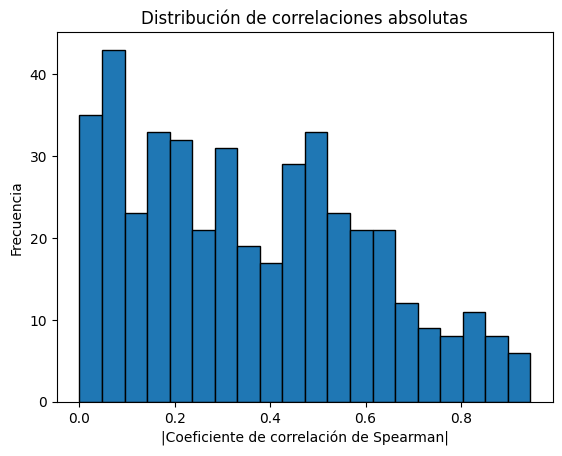

In [21]:
import numpy as np

# Tomar solo el triángulo superior, sin la diagonal, para no duplicar pares ni contar la autocorrelación (=1)
mask = np.triu(np.ones(spearman_matrix.shape), k=1).astype(bool)
values = spearman_matrix.where(mask).stack().values

abs_values = np.abs(values)

plt.hist(abs_values, bins=20, edgecolor='black')
plt.xlabel('|Coeficiente de correlación de Spearman|')
plt.ylabel('Frecuencia')
plt.title('Distribución de correlaciones absolutas')
plt.show()